# 284. What an exact k-mer counts that BLOSUM62 does not, on Pfam seed pairs at 30% identity or less

No kmerseek in this notebook. It asks two things. What can an exact k-mer in a reduced
alphabet see in a pair of related proteins that an aligner scoring with BLOSUM62 cannot? And
is any Pfam seed pair certified by a k-mer alone?

**The one fact this rests on.** An exact k-mer in the H/P alphabet counts a position as a match
whenever the two residues are in the same class, identical or not. BLOSUM62 scores most
same-class substitutions near zero. So the two methods count different things, and the
question is whether the difference ever adds up to a pair that one certifies and the other
does not.

**Data.** Notebook 230's Pfam-A 38.2 seed pair alignments
(`~/data/pfam/230_pfam_seed_pair_alignments.parquet`), pairs with at least 20 aligned
positions and identity 30% or less over aligned positions (`seqid_ali`). The 20-position
floor, lower than notebook 273's 50, keeps short domains in.

**Alphabets.** `protein20`: a match is an identical residue. `hp_thomas_dill2`: H =
`ACFILMVWY`, P = `DEGHKNPQRST`; a match is the same class.

**Per aligned position** (a column where both residues are standard amino acids):

* BLOSUM62 score, converted to bits with the ungapped scale BLAST uses for this matrix,
  $\lambda = 0.3176$ nats per score unit, so bits $= 0.3176 \cdot S / \ln 2 = 0.458 \cdot S$.

**Per pair, both given the Pfam alignment's own diagonal:**

* **Exact run.** The longest stretch of adjacent alignment columns whose residues match in the
  alphabet; a gap column breaks it (`hp_conservation_utils.longest_runs`). Its rarity in bits
  is $k \cdot \log_2(1 / \Pr(\text{match by chance}))$, with
  $\Pr(\text{match by chance}) = \sum_{\text{classes}} f_\text{query}(c)\,f_\text{target}(c)$
  from the pair's own aligned residues, as in notebooks 230 and 273. The pair's run bits are
  the better of its `protein20` run and its `hp_thomas_dill2` run (two tries, worth about one
  bit).
* **Aligner segment.** The largest sum of BLOSUM62 bits over a stretch of adjacent aligned
  columns, no gap inside: the best ungapped local segment on this diagonal.

**The bar.** 24 bits for both, inside the 23-32 bits of the winning kmerseek settings in the
QfO report's winner analysis (quoted in notebook 230). On one diagonal, 24 bits is about
equally rare by chance for both: section 3 measures this by shuffling.

**Then a real aligner.** The pairs a run certifies and the segment does not are re-scored with
a gapped Smith-Waterman alignment of the two domain sequences. This uses Biopython's
`PairwiseAligner` with BLOSUM62 and BLAST's 11/1 gap penalties, so a gap of length $g$ costs
$11 + g$. Its score becomes bits with BLAST's gapped scale for those penalties,
$\lambda = 0.267$.

**Decision rule.** Written after a first look at the counts, so it is not a test fixed
beforehand. A pair is "certified by a k-mer alone" if its run bits reach 24, its aligner
segment does not, and its gapped Smith-Waterman score does not either. The paper may say
"exact k-mers certify pairs BLOSUM62 cannot" only if such pairs exist in more than a handful
of families and the shuffled control gives none.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from Bio.Align import PairwiseAligner, substitution_matrices
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

sys.path.insert(0, str(Path.cwd()))
import hp_conservation_utils as hc

pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(220)

FIG = Path("../figures")
PFAM_ALN = Path("/Users/olga/data/pfam/230_pfam_seed_pair_alignments.parquet")
MIN_COLS = 20
MAX_IDENT = 0.30
BAR = 24.0
LAMBDA_UNGAPPED = 0.3176  # nats per BLOSUM62 score unit, BLAST's ungapped value
LAMBDA_GAPPED_11_1 = 0.267  # BLAST's value for BLOSUM62 with gap open 11, extend 1
HP, P20 = "hp_thomas_dill2", "protein20"
SEED = 284

B62 = substitution_matrices.load("BLOSUM62")
M62 = np.array([[B62[a][b] for b in hc.AA20] for a in hc.AA20], float)
BITS_PER_SCORE = LAMBDA_UNGAPPED / np.log(2)

aln_all = pl.read_parquet(PFAM_ALN)
q, t, pidx, ppos, kept, pcol = hc.aligned_codes(aln_all, MIN_COLS, return_columns=True)
pairs = aln_all[kept]
n = pairs.height
n_pos = np.bincount(pidx, minlength=n)
ident = pairs["seqid_ali"].to_numpy()
low = ident <= MAX_IDENT
print(
    f"Pfam seed pairs with at least {MIN_COLS} aligned positions: {n:_}; "
    f"identity {MAX_IDENT:.0%} or less: {int(low.sum()):_}"
)

# per-position BLOSUM62 bits and class relation
pos_bits = BITS_PER_SCORE * M62[q, t]
cls = hc.class_index(HP)
same_res = q == t
same_cls = cls[q] == cls[t]

Pfam seed pairs with at least 20 aligned positions: 162_897; identity 30% or less: 56_033


## 1. What each method counts at one aligned position

BLOSUM62 bits per aligned position, split by what the two residues have in common, over the
pairs at 20% identity or less. An exact H/P k-mer treats the first two kinds the same (a match)
and the third as the end of the run.

Pfam seed pairs at 20% identity or less, 2_660_687 aligned positions
shape: (3, 4)
┌─────────────────────────────────┬────────────────────┬────────────────────┬────────────────┐
│ kind                            ┆ share_of_positions ┆ mean_blosum62_bits ┆ exact_hp_kmer  │
│ ---                             ┆ ---                ┆ ---                ┆ ---            │
│ str                             ┆ f64                ┆ f64                ┆ str            │
╞═════════════════════════════════╪════════════════════╪════════════════════╪════════════════╡
│ identical residue               ┆ 0.165              ┆ 2.408              ┆ match          │
│ same H/P class, different resi… ┆ 0.522              ┆ 0.018              ┆ match          │
│ different H/P class             ┆ 0.314              ┆ -0.86              ┆ breaks the run │
└─────────────────────────────────┴────────────────────┴────────────────────┴────────────────┘


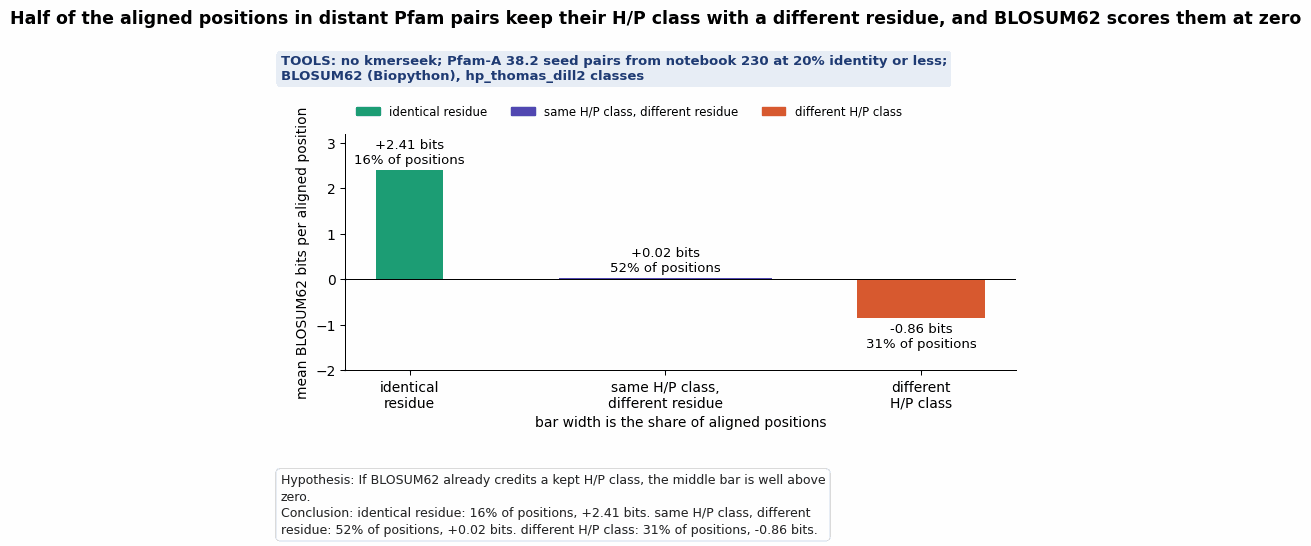

In [2]:
le20 = (ident <= 0.20)[pidx]
rows = []
for lab, m in [
    ("identical residue", same_res),
    ("same H/P class, different residue", same_cls & ~same_res),
    ("different H/P class", ~same_cls),
]:
    mm = m & le20
    rows.append(
        dict(
            kind=lab,
            share_of_positions=mm.sum() / le20.sum(),
            mean_blosum62_bits=pos_bits[mm].mean(),
            exact_hp_kmer="match" if lab != "different H/P class" else "breaks the run",
        )
    )
t1 = pl.DataFrame(rows)
print(f"Pfam seed pairs at 20% identity or less, {int(le20.sum()):_} aligned positions")
print(t1.with_columns(pl.col(pl.Float64).round(3)))

KIND_COLOR = {
    "identical residue": "#1D9E75",
    "same H/P class, different residue": "#534AB7",
    "different H/P class": "#D85A30",
}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(3)
ax.bar(
    x,
    t1["mean_blosum62_bits"],
    width=t1["share_of_positions"].to_numpy() * 1.6,
    color=[KIND_COLOR[k] for k in t1["kind"]],
)
for i, r in enumerate(t1.iter_rows(named=True)):
    ax.text(
        i,
        r["mean_blosum62_bits"] + (0.08 if r["mean_blosum62_bits"] >= 0 else -0.08),
        f"{r['mean_blosum62_bits']:+.2f} bits\n{r['share_of_positions']:.0%} of positions",
        ha="center",
        va="bottom" if r["mean_blosum62_bits"] >= 0 else "top",
        fontsize=9.5,
    )
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(
    x,
    [
        "identical\nresidue",
        "same H/P class,\ndifferent residue",
        "different\nH/P class",
    ],
)
ax.set_ylim(-2.0, 3.2)
ax.set_ylabel("mean BLOSUM62 bits per aligned position")
ax.set_xlabel("bar width is the share of aligned positions")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    handles=[Patch(color=KIND_COLOR[k], label=k) for k in KIND_COLOR],
    loc="lower left",
    bbox_to_anchor=(0, 1.02),
    fontsize=8.5,
    frameon=False,
    ncol=3,
)
hc.finish_figure(
    fig,
    FIG / "284_blosum62_bits_by_residue_relation_pfam_seed_le20pct.png",
    tools="no kmerseek; Pfam-A 38.2 seed pairs from notebook 230 at 20% identity or less; BLOSUM62 (Biopython), hp_thomas_dill2 classes",
    title="Half of the aligned positions in distant Pfam pairs keep their H/P class with a different residue, and BLOSUM62 scores them at zero",
    hypothesis="If BLOSUM62 already credits a kept H/P class, the middle bar is well above zero.",
    conclusion=" ".join(
        f"{r['kind']}: {r['share_of_positions']:.0%} of positions, {r['mean_blosum62_bits']:+.2f} bits."
        for r in t1.iter_rows(named=True)
    ),
    footer_y=-0.08,
)

## 2. One pair, position by position

Two V-SNARE domains (Pfam PF05008): a green alga, `A4RVZ0_OSTLU`, against a ciliate,
`A0BIB1_PARTE`. The pair is one of the 28 found in section 3 whose H/P run reaches 24 bits
while the BLOSUM62 segment does not. The block below shows the run with six columns on each
side. Its rows are the two sequences, `|` where the residues are identical, the two sequences
as H and P, `|` where the classes agree, and the sign of each column's BLOSUM62 bits. The
figure draws the same columns.

In [3]:
def longest_run_columns(qa, ta, alphabet):
    # (length, first column, last column) of the longest run of adjacent columns matching in `alphabet`
    tab = hc.TABLES[alphabet]
    qc = tab[np.frombuffer(qa.encode(), np.uint8)]
    tc = tab[np.frombuffer(ta.encode(), np.uint8)]
    ok = (qc != hc.GAP) & (tc != hc.GAP) & (qc == tc)
    best, cur = (0, -1), 0
    for i, o in enumerate(ok):
        cur = cur + 1 if o else 0
        if cur > best[0]:
            best = (cur, i)
    return best[0], best[1] - best[0] + 1, best[1]


def residue_coordinate(name, gapped, column):
    # residue number (from the name's start coordinate) of the residue at `column`, or the next one
    start = int(name.split("/")[1].split("-")[0])
    return start + sum(1 for c in gapped[:column] if c.isalpha())


EX_QUERY, EX_TARGET = "A4RVZ0_OSTLU/1-94", "A0BIB1_PARTE/7-98"
ex = pairs.filter((pl.col("query") == EX_QUERY) & (pl.col("target") == EX_TARGET)).row(
    0, named=True
)
qa, ta = ex["qaln"].upper(), ex["taln"].upper()
L, c0, c1 = longest_run_columns(qa, ta, HP)
ex_i = int(
    np.flatnonzero(
        (pairs["query"] == EX_QUERY).to_numpy()
        & (pairs["target"] == EX_TARGET).to_numpy()
    )[0]
)
_, _, ex_chance, _ = hc.grouped_evidence(
    q[pidx == ex_i], t[pidx == ex_i], np.zeros(int(n_pos[ex_i]), np.int64), 1, HP
)
ex_chance = float(ex_chance[0])
run_bits_ex = L * -np.log2(ex_chance)
col_bits = np.array(
    [
        BITS_PER_SCORE * B62[a][b] if a.isalpha() and b.isalpha() else np.nan
        for a, b in zip(qa, ta)
    ]
)
seg_bits_ex = np.nansum(col_bits[c0 : c1 + 1])
n_ident_ex = sum(a == b for a, b in zip(qa[c0 : c1 + 1], ta[c0 : c1 + 1]))
print(
    f"{ex['family_id']} ({ex['family']}): {EX_QUERY} against {EX_TARGET}, {ex['seqid_ali']:.0%} identical over "
    f"{int(n_pos[ex_i])} aligned positions; h_query and h_target give Pr(match by chance) = {ex_chance:.3f}"
)
print(
    f"longest H/P run: {L} columns, query residues {residue_coordinate(EX_QUERY, qa, c0)}-"
    f"{residue_coordinate(EX_QUERY, qa, c1 + 1) - 1}, target residues {residue_coordinate(EX_TARGET, ta, c0)}-"
    f"{residue_coordinate(EX_TARGET, ta, c1 + 1) - 1}; {n_ident_ex} of {L} identical"
)
print(
    f"H/P run: {L} x log2(1/{ex_chance:.3f}) = {run_bits_ex:.1f} bits; BLOSUM62 over the same {L} columns: {seg_bits_ex:.1f} bits\n"
)
s, e = max(0, c0 - 6), min(len(qa), c1 + 7)
lines = hc.alignment_lines(qa[s:e], ta[s:e], HP)
bits_row = "".join(
    " " if np.isnan(b) else ("+" if b > 0.5 else ("-" if b < -0.5 else "0"))
    for b in col_bits[s:e]
)
hc.print_alignment(
    [
        ("query", lines["query"]),
        ("identical", lines["identical"]),
        ("target", lines["target"]),
        ("query H/P", lines["query_class"]),
        ("same H/P class", lines["same_class"]),
        ("target H/P", lines["target_class"]),
        ("BLOSUM62 +/0/-", bits_row),
    ],
    width=e - s,
)
print("BLOSUM62 +/0/-: + is more than 0.5 bits, - is less than -0.5 bits, 0 is between")

V-SNARE (PF05008): A4RVZ0_OSTLU/1-94 against A0BIB1_PARTE/7-98, 18% identical over 92 aligned positions; h_query and h_target give Pr(match by chance) = 0.521
longest H/P run: 27 columns, query residues 68-94, target residues 72-98; 6 of 27 identical
H/P run: 27 x log2(1/0.521) = 25.4 bits; BLOSUM62 over the same 27 columns: 19.7 bits

query           SVSDPAVKTPMLNKLRDYKSELAKLKRDAREAS
identical              |         ||   ||   |     
target          TL-SVSYKKELMETVKQYKRDMAKVEKDFKQLQ
query H/P       PHPPPHHPPPHHPPHPPHPPPHHPHPPPHPPHP
same H/P class  || |  |||||||||||||||||||||||||||
target H/P      PH-PHPHPPPHHPPHPPHPPPHHPHPPPHPPHP
BLOSUM62 +/0/-  00 0-00+00++000+0++0++++00++-++00
columns 1-33

BLOSUM62 +/0/-: + is more than 0.5 bits, - is less than -0.5 bits, 0 is between


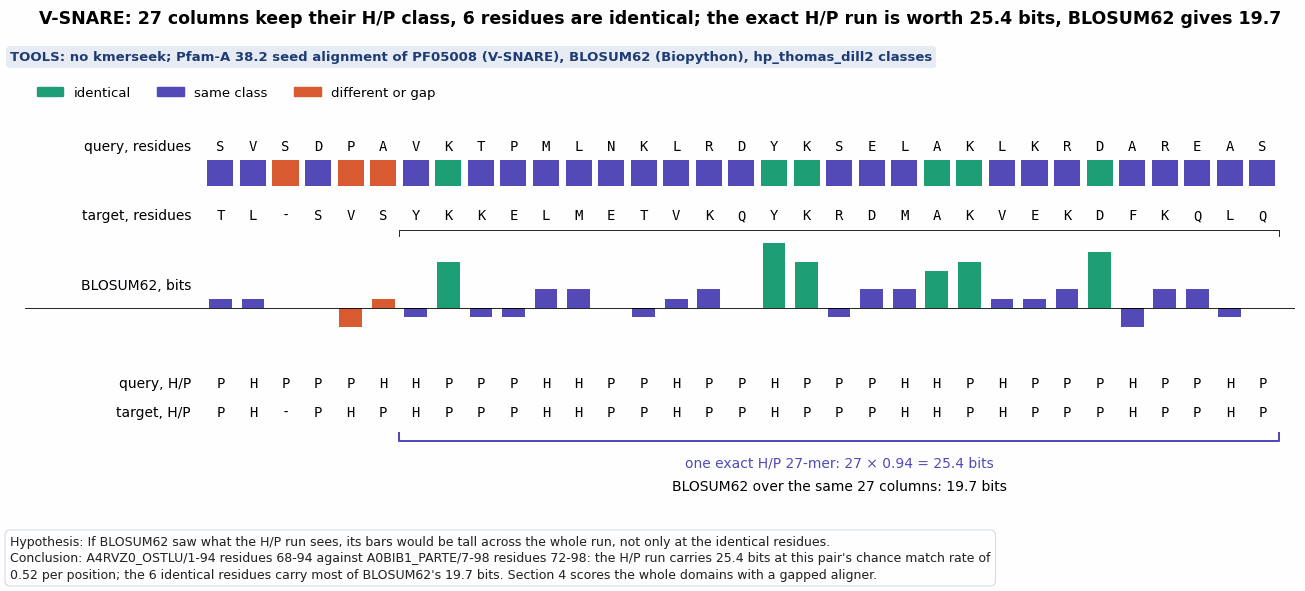

In [4]:
KIND = {"identical": "#1D9E75", "same class": "#534AB7", "different or gap": "#D85A30"}


def kind_of(a, b):
    if not (a.isalpha() and b.isalpha()):
        return "different or gap"
    if a == b:
        return "identical"
    return (
        "same class"
        if hc.TABLES[HP][ord(a)] == hc.TABLES[HP][ord(b)]
        else "different or gap"
    )


cols = list(range(s, e))
fig, ax = plt.subplots(figsize=(13, 4.6))
W = 1.0
for i, c in enumerate(cols):
    a, b = qa[c], ta[c]
    k = kind_of(a, b)
    ax.text(i + 0.5, 5.0, a, ha="center", va="center", fontsize=10, family="monospace")
    ax.add_patch(Rectangle((i + 0.1, 4.3), 0.8, 0.45, color=KIND[k], lw=0))
    ax.text(i + 0.5, 3.8, b, ha="center", va="center", fontsize=10, family="monospace")
    v = col_bits[c]
    if not np.isnan(v):
        ax.add_patch(Rectangle((i + 0.15, 2.2), 0.7, v * 0.35, color=KIND[k], lw=0))
    hq = lines["query_class"][i]
    ht = lines["target_class"][i]
    ax.text(i + 0.5, 0.9, hq, ha="center", va="center", fontsize=10, family="monospace")
    ax.text(i + 0.5, 0.4, ht, ha="center", va="center", fontsize=10, family="monospace")
ax.axhline(2.2, xmin=0, xmax=1, color="black", lw=0.6)
r0, r1 = c0 - s, c1 - s + 1
ax.plot([r0, r0, r1, r1], [0.05, -0.1, -0.1, 0.05], color=KIND["same class"], lw=1.5)
ax.text(
    (r0 + r1) / 2,
    -0.35,
    f"one exact H/P {L}-mer: {L} × {-np.log2(ex_chance):.2f} = {run_bits_ex:.1f} bits",
    ha="center",
    va="top",
    fontsize=10,
    color=KIND["same class"],
)
ax.plot([r0, r0, r1, r1], [3.45, 3.55, 3.55, 3.45], color="black", lw=0.6)
ax.text(
    (r0 + r1) / 2,
    -0.75,
    f"BLOSUM62 over the same {L} columns: {seg_bits_ex:.1f} bits",
    ha="center",
    va="top",
    fontsize=10,
)
for y, lab in [
    (5.0, "query, residues"),
    (3.8, "target, residues"),
    (2.6, "BLOSUM62, bits"),
    (0.9, "query, H/P"),
    (0.4, "target, H/P"),
]:
    ax.text(-0.4, y, lab, ha="right", va="center", fontsize=10)
ax.set_xlim(-5.5, len(cols) + 0.5)
ax.set_ylim(-1.3, 5.6)
ax.axis("off")
ax.legend(
    handles=[Patch(color=v, label=k) for k, v in KIND.items()],
    loc="lower left",
    bbox_to_anchor=(0, 1.0),
    ncol=3,
    frameon=False,
    fontsize=9.5,
)
hc.finish_figure(
    fig,
    FIG / "284_one_pair_hp_run_vs_blosum62_segment_v_snare.png",
    tools="no kmerseek; Pfam-A 38.2 seed alignment of PF05008 (V-SNARE), BLOSUM62 (Biopython), hp_thomas_dill2 classes",
    title=f"V-SNARE: {L} columns keep their H/P class, {n_ident_ex} residues are identical; the exact H/P run is worth {run_bits_ex:.1f} bits, BLOSUM62 gives {seg_bits_ex:.1f}",
    hypothesis="If BLOSUM62 saw what the H/P run sees, its bars would be tall across the whole run, not only at the identical residues.",
    conclusion=f"{EX_QUERY} residues {residue_coordinate(EX_QUERY, qa, c0)}-{residue_coordinate(EX_QUERY, qa, c1 + 1) - 1} against "
    f"{EX_TARGET} residues {residue_coordinate(EX_TARGET, ta, c0)}-{residue_coordinate(EX_TARGET, ta, c1 + 1) - 1}: "
    f"the H/P run carries {run_bits_ex:.1f} bits at this pair's chance match rate of {ex_chance:.2f} per position; "
    f"the {n_ident_ex} identical residues carry most of BLOSUM62's {seg_bits_ex:.1f} bits. Section 4 scores the whole domains with a gapped aligner.",
    footer_y=-0.02,
)

## 3. The same bar for both, on every pair

Each pair's exact run (the better of `protein20` and `hp_thomas_dill2`) against its best
ungapped BLOSUM62 segment, both on the Pfam alignment's diagonal, both against 24 bits.
Pairs are split by length (20-59 aligned positions against 60 or more) and identity
(20% or less against 20-30%). The shuffled control keeps each pair's residues and alignment
columns and shuffles the target's residues among its aligned positions, once per pair, with
three seeds.

In [5]:
def run_bits_per_pair(tt):
    out = {}
    for a in (P20, HP):
        _, _, ch, _ = hc.grouped_evidence(q, tt, pidx, n, a)
        out[a] = hc.longest_runs(q, tt, pidx, n, pcol, a) * -np.log2(ch)
    return out


def segment_bits_per_pair(tt):
    # largest sum of BLOSUM62 bits over adjacent aligned columns with no gap inside (Kadane per pair)
    sc = BITS_PER_SCORE * M62[q, tt]
    restart = np.r_[True, (pidx[1:] != pidx[:-1]) | (pcol[1:] != pcol[:-1] + 1)]
    best = np.full(n, -np.inf)
    cur = 0.0
    for i in range(sc.size):
        cur = sc[i] if (restart[i] or cur < 0) else cur + sc[i]
        if cur > best[pidx[i]]:
            best[pidx[i]] = cur
    return best


runs = run_bits_per_pair(t)
run_best = np.maximum(runs[P20], runs[HP])
seg = segment_bits_per_pair(t)

shuf = []
for seed in (SEED, SEED + 1, SEED + 2):
    rng = np.random.default_rng(seed)
    order = np.argsort(
        pidx * 10**9 + rng.integers(0, 10**9, size=pidx.size), kind="stable"
    )
    t_shuf = t[
        order
    ]  # a permutation within each pair: order sorts by pair, then by a random key
    assert np.array_equal(np.bincount(pidx * 20 + t_shuf), np.bincount(pidx * 20 + t))
    runs_shuf = run_bits_per_pair(t_shuf)
    shuf.append(
        (np.maximum(runs_shuf[P20], runs_shuf[HP]), segment_bits_per_pair(t_shuf))
    )
run_best_shuf, seg_shuf = shuf[0]

rows = []
for len_lab, lm in [
    ("short, 20-59 positions", (n_pos >= MIN_COLS) & (n_pos < 60)),
    ("long, 60 or more", n_pos >= 60),
]:
    for id_lab, im in [
        ("20% or less", ident <= 0.20),
        ("20-30%", (ident > 0.20) & (ident <= MAX_IDENT)),
    ]:
        m = lm & im
        r_ok, s_ok = run_best[m] >= BAR, seg[m] >= BAR
        rows.append(
            dict(
                length=len_lab,
                identity=id_lab,
                pairs=int(m.sum()),
                run_only=int((r_ok & ~s_ok).sum()),
                run_only_hp=int(((runs[HP][m] >= BAR) & ~s_ok).sum()),
                segment_only=int((s_ok & ~r_ok).sum()),
                both=int((r_ok & s_ok).sum()),
                neither=int((~r_ok & ~s_ok).sum()),
                run_only_pct=100 * (r_ok & ~s_ok).mean(),
                segment_only_pct=100 * (s_ok & ~r_ok).mean(),
                shuffled_run_pct=100 * (run_best_shuf[m] >= BAR).mean(),
                shuffled_segment_pct=100 * (seg_shuf[m] >= BAR).mean(),
            )
        )
t3 = pl.DataFrame(rows)
print(f"Both methods against {BAR:.0f} bits on the Pfam alignment's diagonal")
print(t3.with_columns(pl.col(pl.Float64).round(2)))

run_only = low & (run_best >= BAR) & (seg < BAR)
hp_only = low & (runs[HP] >= BAR) & (seg < BAR)
p20_only = low & (runs[P20] >= BAR) & (seg < BAR)
print(
    f"\nPairs at {MAX_IDENT:.0%} identity or less that a run certifies and the segment does not: {int(run_only.sum())} "
    f"of {int(low.sum()):_}; through an identical-residue run {int(p20_only.sum())}, through an H/P run {int(hp_only.sum())}, "
    f"through both {int((p20_only & hp_only).sum())}"
)
p20_lens = hc.longest_runs(q, t, pidx, n, pcol, P20)[p20_only]
print(
    "identical-residue run lengths among them:",
    {int(k): int(v) for k, v in zip(*np.unique(p20_lens, return_counts=True))},
)
for seed, (rb, sb) in zip((SEED, SEED + 1, SEED + 2), shuf):
    print(
        f"shuffled targets (seed {seed}), pairs at {MAX_IDENT:.0%} identity or less: {int((rb[low] >= BAR).sum())} pairs reach "
        f"{BAR:.0f} bits by a run and {int((sb[low] >= BAR).sum())} by a segment"
    )
p20_chance_bits = -np.log2(hc.grouped_evidence(q, t, pidx, n, P20)[2])
print(
    f"bits per identical residue in a protein20 run, log2(1/chance), over the {int(p20_only.sum())} pairs certified by one: "
    f"mean {p20_chance_bits[p20_only].mean():.2f}, range {p20_chance_bits[p20_only].min():.2f}-{p20_chance_bits[p20_only].max():.2f}; "
    f"mean BLOSUM62 bits of the identical residues inside those runs: "
    f"{pos_bits[same_res & p20_only[pidx]].mean():.2f} over all identical positions of those pairs"
)
print(
    f"median segment bits of the run-only pairs: {np.median(seg[run_only]):.1f}; "
    f"{100 * ((seg[run_only] >= 21) & (seg[run_only] < BAR)).mean():.0f}% are between 21 and 24 bits"
)

Both methods against 24 bits on the Pfam alignment's diagonal
shape: (4, 12)
┌────────────────────────┬─────────────┬───────┬──────────┬─────────────┬──────────────┬──────┬─────────┬──────────────┬──────────────────┬──────────────────┬──────────────────────┐
│ length                 ┆ identity    ┆ pairs ┆ run_only ┆ run_only_hp ┆ segment_only ┆ both ┆ neither ┆ run_only_pct ┆ segment_only_pct ┆ shuffled_run_pct ┆ shuffled_segment_pct │
│ ---                    ┆ ---         ┆ ---   ┆ ---      ┆ ---         ┆ ---          ┆ ---  ┆ ---     ┆ ---          ┆ ---              ┆ ---              ┆ ---                  │
│ str                    ┆ str         ┆ i64   ┆ i64      ┆ i64         ┆ i64          ┆ i64  ┆ i64     ┆ f64          ┆ f64              ┆ f64              ┆ f64                  │
╞════════════════════════╪═════════════╪═══════╪══════════╪═════════════╪══════════════╪══════╪═════════╪══════════════╪══════════════════╪══════════════════╪══════════════════════╡
│ short, 20-5

identical-residue run lengths among them: {6: 127, 7: 97, 8: 21, 9: 7, 10: 2}
shuffled targets (seed 284), pairs at 30% identity or less: 1 pairs reach 24 bits by a run and 2 by a segment
shuffled targets (seed 285), pairs at 30% identity or less: 0 pairs reach 24 bits by a run and 1 by a segment
shuffled targets (seed 286), pairs at 30% identity or less: 0 pairs reach 24 bits by a run and 2 by a segment


bits per identical residue in a protein20 run, log2(1/chance), over the 254 pairs certified by one: mean 4.00, range 3.14-4.38; mean BLOSUM62 bits of the identical residues inside those runs: 2.45 over all identical positions of those pairs
median segment bits of the run-only pairs: 21.3; 57% are between 21 and 24 bits


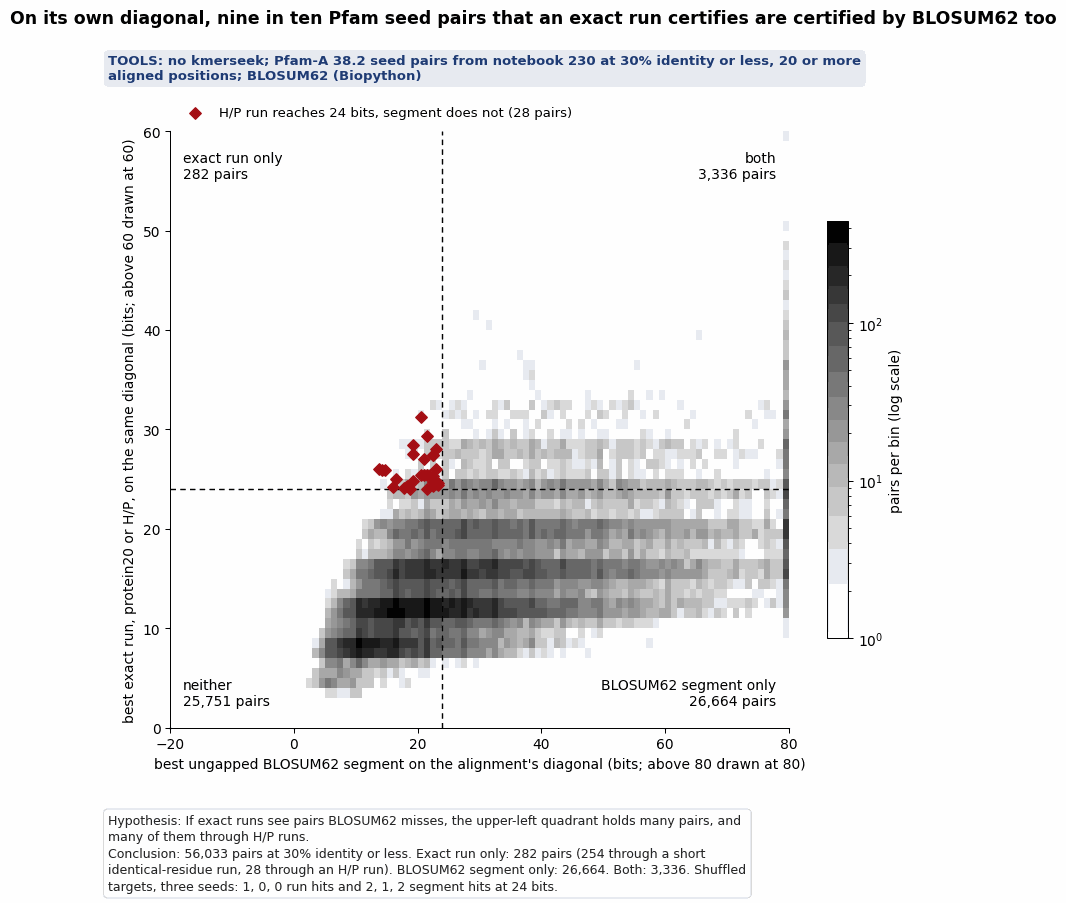

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 7))
sel = low
xb, yb = seg[sel], run_best[sel]
h = ax.hist2d(
    np.clip(xb, -20, 80),
    np.clip(yb, 0, 60),
    bins=[100, 60],
    range=[[-20, 80], [0, 60]],
    cmap="Greys",
    norm="log",
    zorder=1,
)
plt.colorbar(h[3], ax=ax, label="pairs per bin (log scale)", shrink=0.7)
ax.axvline(BAR, color="black", lw=1, ls=(0, (4, 3)))
ax.axhline(BAR, color="black", lw=1, ls=(0, (4, 3)))
ax.scatter(
    seg[hp_only],
    runs[HP][hp_only],
    marker="D",
    s=34,
    color="#a50f15",
    zorder=3,
    label=f"H/P run reaches {BAR:.0f} bits, segment does not ({int(hp_only.sum())} pairs)",
)
q_ = {
    "segment only": int(((seg[sel] >= BAR) & (run_best[sel] < BAR)).sum()),
    "both": int(((seg[sel] >= BAR) & (run_best[sel] >= BAR)).sum()),
    "run only": int(((seg[sel] < BAR) & (run_best[sel] >= BAR)).sum()),
    "neither": int(((seg[sel] < BAR) & (run_best[sel] < BAR)).sum()),
}
for (x_, y_, lab), ha in [
    ((78, 2, f"BLOSUM62 segment only\n{q_['segment only']:,} pairs"), "right"),
    ((78, 58, f"both\n{q_['both']:,} pairs"), "right"),
    ((-18, 58, f"exact run only\n{q_['run only']:,} pairs"), "left"),
    ((-18, 2, f"neither\n{q_['neither']:,} pairs"), "left"),
]:
    ax.text(
        x_,
        y_,
        lab,
        ha=ha,
        va="bottom" if y_ < 30 else "top",
        fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2),
    )
ax.set_xlabel(
    "best ungapped BLOSUM62 segment on the alignment's diagonal (bits; above 80 drawn at 80)"
)
ax.set_ylabel(
    "best exact run, protein20 or H/P, on the same diagonal (bits; above 60 drawn at 60)"
)
ax.set_xlim(-20, 80)
ax.set_ylim(0, 60)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False, fontsize=9.5)
hc.finish_figure(
    fig,
    FIG / "284_exact_run_bits_vs_blosum62_segment_bits_pfam_seed_le30pct.png",
    tools="no kmerseek; Pfam-A 38.2 seed pairs from notebook 230 at 30% identity or less, 20 or more aligned positions; BLOSUM62 (Biopython)",
    title=f"On its own diagonal, nine in ten Pfam seed pairs that an exact run certifies are certified by BLOSUM62 too",
    hypothesis="If exact runs see pairs BLOSUM62 misses, the upper-left quadrant holds many pairs, and many of them through H/P runs.",
    conclusion=(
        f"{int(low.sum()):,} pairs at {MAX_IDENT:.0%} identity or less. Exact run only: {q_['run only']:,} pairs "
        f"({int(p20_only.sum())} through a short identical-residue run, {int(hp_only.sum())} through an H/P run). "
        f"BLOSUM62 segment only: {q_['segment only']:,}. Both: {q_['both']:,}. Shuffled targets, three seeds: "
        f"{', '.join(str(int((rb[low] >= BAR).sum())) for rb, _ in shuf)} run hits and "
        f"{', '.join(str(int((sb[low] >= BAR).sum())) for _, sb in shuf)} segment hits at {BAR:.0f} bits."
    ),
    footer_y=-0.04,
)

## 4. The pairs a run certifies alone, scored by a gapped aligner

Section 3 gives the aligner only one diagonal and no gaps, which is what an exact seed gets.
A real aligner tries every offset and bridges gaps. Each pair a run certifies and the segment
does not is re-scored with a gapped Smith-Waterman alignment of the two domain sequences, the
seed alignment rows with gaps removed. The scoring is BLOSUM62 with a gap of length $g$
costing $11 + g$, and bits $= 0.267 \cdot S / \ln 2$. The figure shows the 28 pairs certified
by an H/P run.

In [7]:
aligner = PairwiseAligner()
aligner.mode = "local"
aligner.substitution_matrix = B62
aligner.open_gap_score = -12  # first gap residue 12, each further one 1: BLAST's 11 + g
aligner.extend_gap_score = -1
GAPPED_BITS_PER_SCORE = LAMBDA_GAPPED_11_1 / np.log(2)


def domain_seq(gapped):
    return (
        "".join(c for c in gapped.upper() if c.isalpha())
        .replace("U", "X")
        .replace("O", "X")
    )


idx_run_only = np.flatnonzero(run_only)
sw_bits = np.full(n, np.nan)
for i in idx_run_only:
    r = pairs.row(int(i), named=True)
    sw_bits[i] = GAPPED_BITS_PER_SCORE * aligner.score(
        domain_seq(r["qaln"]), domain_seq(r["taln"])
    )
print(
    f"Gapped Smith-Waterman reaches {BAR:.0f} bits on {int((sw_bits[run_only] >= BAR).sum())} of the {int(run_only.sum())} "
    f"run-only pairs, and on {int((sw_bits[hp_only] >= BAR).sum())} of the {int(hp_only.sum())} certified by an H/P run"
)
print(
    f"V-SNARE pair: gapped Smith-Waterman {sw_bits[ex_i]:.1f} bits"
    if not np.isnan(sw_bits[ex_i])
    else "V-SNARE pair is not in the run-only set"
)

hp_tab = (
    pairs.with_row_index("row")
    .filter(pl.Series(hp_only))
    .select("row", "family_id", "query", "target", "seqid_ali")
    .with_columns(
        aligned_positions=pl.Series(n_pos[hp_only]),
        hp_run_bits=pl.Series(runs[HP][hp_only]),
        segment_bits=pl.Series(seg[hp_only]),
        gapped_sw_bits=pl.Series(sw_bits[hp_only]),
    )
    .sort("hp_run_bits", descending=True)
)
print(
    f"\nThe {hp_tab.height} pairs certified by an H/P run and not by the BLOSUM62 segment"
)
print(hp_tab.drop("row").with_columns(pl.col(pl.Float64).round(1)))
left = hp_tab.filter(pl.col("gapped_sw_bits") < BAR)
print(
    f"\nStill under {BAR:.0f} bits with the gapped aligner: {left.height} pairs, families "
    + ", ".join(left["family_id"].to_list())
)

# BLAST's K, left out above: the bit score is lambda S / ln 2 - log2 K
K_UNGAPPED, K_GAPPED = (
    0.134,
    0.041,
)  # BLAST's values for BLOSUM62, ungapped and with gap open 11, extend 1
seg_k = seg + np.log2(1 / K_UNGAPPED)
sw_k = sw_bits + np.log2(1 / K_GAPPED)
left_k = hp_only & (sw_k < BAR)
print(
    f"With K added: the ungapped segment gains {np.log2(1 / K_UNGAPPED):.1f} bits and passes {BAR:.0f} on "
    f"{int((seg_k[run_only] >= BAR).sum())} of the {int(run_only.sum())} run-only pairs; the gapped score gains "
    f"{np.log2(1 / K_GAPPED):.1f} bits and passes on {int(((sw_k >= BAR) & hp_only & (sw_bits < BAR)).sum())} more of the "
    f"{left.height} H/P pairs, leaving {int(left_k.sum())}: "
    + ", ".join(pairs["family_id"].to_numpy()[left_k])
)

Gapped Smith-Waterman reaches 24 bits on 180 of the 282 run-only pairs, and on 17 of the 28 certified by an H/P run
V-SNARE pair: gapped Smith-Waterman 30.0 bits

The 28 pairs certified by an H/P run and not by the BLOSUM62 segment
shape: (28, 8)
┌─────────────────────┬────────────────────────────┬────────────────────────────┬───────────┬───────────────────┬─────────────┬──────────────┬────────────────┐
│ family_id           ┆ query                      ┆ target                     ┆ seqid_ali ┆ aligned_positions ┆ hp_run_bits ┆ segment_bits ┆ gapped_sw_bits │
│ ---                 ┆ ---                        ┆ ---                        ┆ ---       ┆ ---               ┆ ---         ┆ ---          ┆ ---            │
│ str                 ┆ str                        ┆ str                        ┆ f64       ┆ i64               ┆ f64         ┆ f64          ┆ f64            │
╞═════════════════════╪════════════════════════════╪════════════════════════════╪═══════════╪═══════════════════╪

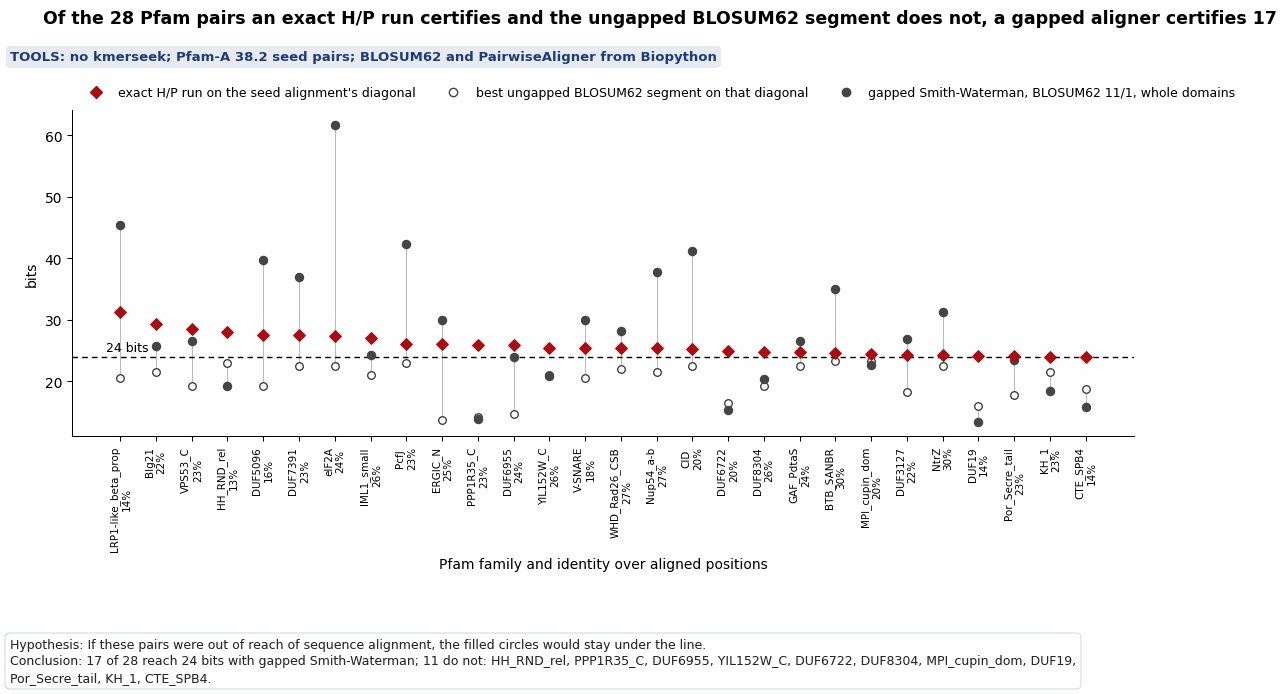

In [8]:
fig, ax = plt.subplots(figsize=(13, 5.2))
xs = np.arange(hp_tab.height)
ax.axhline(BAR, color="black", lw=1, ls=(0, (4, 3)))
ax.text(-0.4, BAR + 0.4, f"{BAR:.0f} bits", fontsize=9, va="bottom")
for i, r in enumerate(hp_tab.iter_rows(named=True)):
    ax.plot(
        [i, i],
        [r["segment_bits"], r["gapped_sw_bits"]],
        color="#BBBBBB",
        lw=1,
        zorder=1,
    )
ax.scatter(
    xs,
    hp_tab["segment_bits"],
    marker="o",
    s=30,
    facecolor="white",
    edgecolor="#444444",
    zorder=2,
)
ax.scatter(xs, hp_tab["gapped_sw_bits"], marker="o", s=34, color="#444444", zorder=3)
ax.scatter(xs, hp_tab["hp_run_bits"], marker="D", s=34, color="#a50f15", zorder=4)
ax.set_xticks(
    xs,
    [f"{r['family_id']}\n{r['seqid_ali']:.0%}" for r in hp_tab.iter_rows(named=True)],
    fontsize=7.5,
    rotation=90,
)
ax.set_ylabel("bits")
ax.set_xlabel("Pfam family and identity over aligned positions")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(
    handles=[
        Line2D(
            [],
            [],
            marker="D",
            color="#a50f15",
            ls="",
            ms=6,
            label="exact H/P run on the seed alignment's diagonal",
        ),
        Line2D(
            [],
            [],
            marker="o",
            mfc="white",
            mec="#444444",
            color="#444444",
            ls="",
            ms=6,
            label="best ungapped BLOSUM62 segment on that diagonal",
        ),
        Line2D(
            [],
            [],
            marker="o",
            color="#444444",
            ls="",
            ms=6,
            label="gapped Smith-Waterman, BLOSUM62 11/1, whole domains",
        ),
    ],
    loc="lower left",
    bbox_to_anchor=(0, 1.0),
    frameon=False,
    fontsize=9,
    ncol=3,
)
n_left = int((hp_tab["gapped_sw_bits"] < BAR).sum())
hc.finish_figure(
    fig,
    FIG / "284_hp_run_only_pairs_vs_gapped_smith_waterman.png",
    tools="no kmerseek; Pfam-A 38.2 seed pairs; BLOSUM62 and PairwiseAligner from Biopython",
    title=f"Of the {hp_tab.height} Pfam pairs an exact H/P run certifies and the ungapped BLOSUM62 segment does not, a gapped aligner certifies {hp_tab.height - n_left}",
    hypothesis="If these pairs were out of reach of sequence alignment, the filled circles would stay under the line.",
    conclusion=f"{hp_tab.height - n_left} of {hp_tab.height} reach {BAR:.0f} bits with gapped Smith-Waterman; {n_left} do not"
    + (": " + ", ".join(left["family_id"].to_list()) if n_left else "")
    + ".",
    footer_y=-0.1,
)

## 5. Summary and conclusions

**Question.** Does an exact k-mer in a reduced alphabet certify any Pfam seed pair at 30%
identity or less that an aligner scoring with BLOSUM62 cannot?

**Answer.** Not in practice. Almost every pair a run certifies is certified by BLOSUM62 too, and
a gapped aligner catches most of the rest.

1. The two methods do count different things. In pairs at 20% identity or less, 52% of aligned
   positions keep their H/P class with a different residue, and BLOSUM62 scores those at +0.02
   bits on average. An identical residue scores +2.41 bits and a class change -0.86 (section 1).
   An exact H/P k-mer counts the first two kinds as matches.
2. On the seed alignment's diagonal, with 24 bits as the bar for both, 282 of 56,033 pairs are
   certified by an exact run and not by the best ungapped BLOSUM62 segment. 254 of them are
   short runs of identical residues (6 to 10 residues). In those pairs a run credits each
   identical residue about 4.0 bits, log2(1 / chance), and BLOSUM62 about 2.5. Only 28 come
   through an H/P run. The other way round, 26,664 pairs are certified by the segment and not
   by a run (section 3). Shuffling the target's residues among its aligned positions gives
   1, 0 and 0 runs and 2, 1 and 2 segments at 24 bits over three seeds, so the bar is about
   equally rare by chance for both, and the decision rule's "none" is met for two seeds of three.
3. A gapped Smith-Waterman alignment of the whole domains, BLOSUM62 11/1, reaches 24 bits on
   180 of the 282 and on 17 of the 28 (section 4). The V-SNARE pair of section 2 scores 30.0
   bits. Of the 21 substitutions in its run, 11 score above zero in BLOSUM62 (K-R and L-M
   three times each, L-V twice, D-E, E-K), 3 at zero and 7 below, and the aligner adds the
   rest of the domain.
4. The 11 pairs that neither aligner certifies rest on one H/P run each, in 11 families, 4 of
   them DUFs. That is a handful, not a class of finds.

**Limits.**
* A column holding a non-standard letter (X, B, Z, U, O) breaks a run and a segment, like a
  gap, and is left out of the composition; the gapped aligner sees those residues.
* Both methods were handed the Pfam alignment's diagonal. A database search has to find it,
  and pays about $\log_2(\text{query length} \times \text{target length} \times \text{database size})$,
  30 bits or more, to do so; neither side's bits here include that.
* Run bits treat positions as independent. H/P classes repeat along helices, strands and
  membrane segments, so a run's rarity is overstated where the pattern is periodic. Shuffling
  within the pair does not test this; a null that keeps secondary structure would.
* The chance match rate uses each pair's own composition; BLOSUM62's $\lambda$ uses a fixed
  background, so the aligner gets no composition correction.
* BLAST's constant $K$ is left out of both sides: $-\log_2 K$ is about 2.9 bits for the
  ungapped segment ($K = 0.134$), 4.6 bits for the gapped score ($K = 0.041$), and
  $\log_2(1 / (1 - \Pr(\text{match by chance})))$ is 0.1 to 1 bit for the run. Adding them
  favours the aligner: 141 of the 282 run-only pairs then pass on the ungapped segment, and 5
  more of the 11 pass with the gapped score, leaving 6.
* Pfam seed families are built from alignments, so this set cannot hold a pair that no
  alignment supports. It can only show that, inside alignment-defined families, k-mers add
  nothing an aligner lacks.

**Decision.** The paper cannot say that exact k-mers certify Pfam pairs BLOSUM62 misses. What
an exact H/P k-mer counts and BLOSUM62 does not is a class kept with a residue change that
BLOSUM62 scores at zero: hydrophobic for hydrophobic, polar for polar, outside the pairs it
rewards. Pairs certified by that alone have to be looked for where features are defined by
such a pattern rather than by residue conservation. That means membrane and amphipathic
helices, strand alternation, charge and hydrophobic patterning in disordered regions,
collagen-like repeats and linear motifs, which is where notebook 244's hero examples live. The
test to run next is this notebook's comparison on the Swiss-Prot feature instances of notebook
244 (COILED, REGION, REPEAT, MOTIF, ZN_FING): an exact run per alphabet, a gapped aligner, a
matched decoy, and a single-sequence predictor as the control to beat. A find counts only if
the k-mer certifies it, the aligner and the predictor do not, and a decoy of the same length
and composition does not match as well.